# NLP Final — AI-assisted lost and found matching
**ICS 3202 | Deliverable 3 | Strathmore University**

Alex Muriithi (177298), Nimrod Kobia (168357), Louis Muturi (191603)

### What problem are we solving?
When a student loses an item, office staff may have to search through many found reports. Our system reads the student's description and suggests the most similar items, starting with the best match.

**Input:** a lost-item report. **Output:** a ranked list of up to five possible matches, with reasons to help staff review them. A match is a suggestion, not proof that the student owns the item.

We started with [Logistic Regression](LogisticRegression_Baseline.ipynb), which classifies pairs of reports. The final application uses **Natural Language Processing (NLP)** with TF-IDF and cosine similarity to rank written descriptions.

### How to follow this notebook
Read the short explanation before each important code cell, then look at the result below it. The notebook follows the full data mining process.

| Stage | Where to look |
|---|---|
| Understand the problem and collect data | Introduction and section 1 |
| Prepare and check the data | Section 2 |
| Build the base and NLP models | Sections 3–4 |
| Compare, select settings and test | Sections 5–6 |
| Test the real matching logic and explain results | Sections 7–7A |
| Connect to the application and review limitations | Sections 8–9 |

**Running the notebook:** install requirements.txt and run all cells from within the repository using a fresh Python kernel. The saved outputs were generated by a successful clean-kernel run. The optional HTTP preview is separate from the Android application test.

## 1. Data collection and understanding

### Where did the data come from?
We use two sources because they answer different questions.

| Source | Purpose |
|---|---|
| Strathmore Lost and Found Office inventory | Understand the number and types of unclaimed items at the university. |
| Fictional lost and found reports | Develop and test matching using examples with known expected answers. |

The office records contain totals rather than individual lost and found descriptions. We therefore cannot use those totals to teach the model which two reports describe the same item.

The controlled examples are not genuine campus matching records. They give us a starting point for testing; independent review of the examples and their labels is still needed.

### 1.1 Set up and examine the office records
The next cells load the Python tools, locate the project folder, read the inventory CSV (a table stored as text), and add up quantities by period and category. We also check whether the disposal destination is missing.

In [1]:
import csv, json, sys, platform
from pathlib import Path
from tempfile import TemporaryDirectory
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "scripts/prepare_ranking_benchmark.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within SemProject_MLEngine")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("Repository:", ROOT.name)

Python: 3.12.16 | scikit-learn: 1.9.1
Repository: SemProject_MLEngine


In [2]:
inventory_path = ROOT / 'data/raw/campus/office_inventory_aggregate.csv'
with inventory_path.open(encoding='utf-8', newline='') as stream:
    inventory = list(csv.DictReader(stream))
totals = defaultdict(int); category_totals = defaultdict(lambda: defaultdict(int))
for row in inventory:
    quantity = int(row['quantity'])
    totals[row['period']] += quantity
    category_totals[row['period']][row['category']] += quantity
print('period | rows | quantity | missing disposal destination')
for period in totals:
    rows = [row for row in inventory if row['period'] == period]
    missing_destination = sum(not row['dispose_to'].strip() for row in rows)
    print(f"{period} | {len(rows)} | {totals[period]} | {missing_destination}")
    print('  category totals:', dict(category_totals[period]))
print('Used for training or scoring: no. The table has no item-level match labels.')

period | rows | quantity | missing disposal destination
2026-06_07 | 33 | 388 | 1
  category totals: {'electronics': 125, 'calculators': 23, 'clothing': 58, 'other': 182}
2026-08 | 24 | 299 | 0
  category totals: {'electronics': 95, 'calculators': 7, 'clothing': 56, 'other': 141}
Used for training or scoring: no. The table has no item-level match labels.


**Why use a chart?** A category breakdown makes it easier to see the kinds of items handled by the office than reading the inventory rows one by one.

,electronics,calculators,clothing,other
2026-06_07,125,23,58,182
2026-08,95,7,56,141


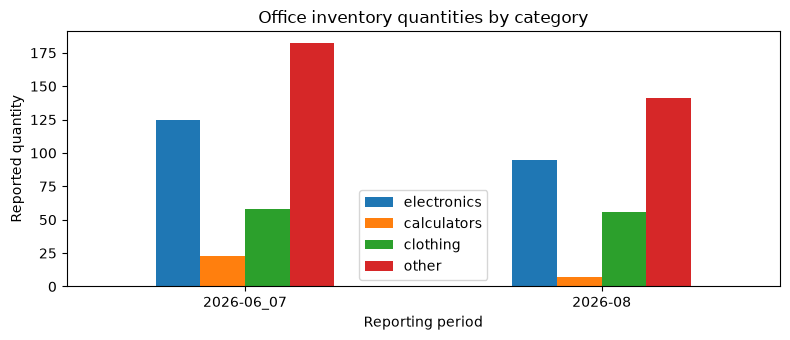

In [3]:
inventory_summary = pd.DataFrame(category_totals).T.fillna(0)
display(inventory_summary)
ax = inventory_summary.plot(kind='bar', figsize=(8, 3.5), rot=0)
ax.set(title='Office inventory quantities by category', xlabel='Reporting period', ylabel='Reported quantity')
plt.tight_layout()
plt.show()

**What we learn:** the two periods contain 388 and 299 reported items, a combined quantity of 687. Electronics account for a large share of the recorded inventory. These are quantities, not 687 unique matching examples. One disposal destination is missing; it is kept as unknown rather than guessed.

## 2. Data preparation: create labelled examples

### How do we make a dataset for matching?
Each of the 24 controlled item groups contains a description of a found item and a corresponding lost report. A **label** tells us the expected answer: 1 means the same item; 0 means a different item.

We compare the eight lost reports in each group of eight items with the eight found reports in that split. This creates 64 pairs per split: 8 correct pairs and 56 incorrect pairs. Across the three splits, we obtain 192 labelled pairs. We add three lost reports that have no intended match to check how the system behaves when an item is absent.

The next cell reads the original fictional examples, builds the found and lost tables, creates the pair labels and saves the evaluation queries and candidate inventory in a temporary folder. Each report has an identifier so we can trace it back to its source.

In [4]:
# Use the same fixture files and transformations as prepare_ranking_benchmark.py.
SOURCE = ROOT / "data" / "fixtures" / "ranking"
_NOTEBOOK_TMP = TemporaryDirectory(prefix="nlp-ranking-")
RUN_DIR = Path(_NOTEBOOK_TMP.name)
DATA = RUN_DIR / "ranking"
output_dir = DATA
def read(name):
    with (SOURCE / name).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def write(output_dir, name, fields, rows):
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / name).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

items = read("controlled_items.csv")
absent = read("no_match_queries.csv")
if len({item["item_group_id"] for item in items}) != len(items):
    raise ValueError("Controlled item groups must be unique")
inventory = read("../../raw/campus/office_inventory_aggregate.csv")
quantities = Counter()
for row in inventory:
    quantities[row["period"]] += int(row["quantity"])
if dict(quantities) != {"2026-06_07": 388, "2026-08": 299}:
    raise ValueError(f"Aggregate transcription does not reconcile: {dict(quantities)}")
found = []
lost = []
labels = []
queries = []
for item in items:
    group = item["item_group_id"]
    found.append(dict(found_id=f"f-{group}", item_group_id=group, category=item["category"],
                      description=item["found_description"], colour=item["colour"], brand=item["brand"],
                      distinguishing_attributes="", location=item["location"], event_date="",
                      report_status="active", source_type=item["source_type"], split=item["split"]))
    lost.append(dict(lost_id=f"l-{group}", item_group_id=group, category=item["category"],
                     description=item["lost_description"], colour=item["colour"], brand=item["brand"],
                     last_seen_location=item["location"], date_lost="", source_type=item["source_type"],
                     split=item["split"]))
for item in items:
    group, split = item["item_group_id"], item["split"]
    lost_id = f"l-{group}"
    for candidate in items:
        if candidate["split"] != split:
            continue
        same = candidate["item_group_id"] == group
        labels.append(dict(lost_id=lost_id, found_id=f"f-{candidate['item_group_id']}",
                           label=int(same), label_source="controlled_fictional_identity",
                           item_group_id=group, reviewer="pending_independent_review", split=split))
    queries.append(dict(query_id=f"q-{group}", lost_id=lost_id, relevant_found_ids=f"f-{group}",
                        candidate_pool_id="all_constructed_found_v1", has_match=1, split=split))
for row in absent:
    lost.append(dict(lost_id=row["lost_id"], item_group_id=row["lost_id"], category=row["category"],
                     description=row["description"], colour=row["colour"], brand=row["brand"],
                     last_seen_location=row["location"], date_lost="", source_type=row["source_type"],
                     split=row["split"]))
    queries.append(dict(query_id=f"q-{row['lost_id']}", lost_id=row["lost_id"], relevant_found_ids="",
                        candidate_pool_id="all_constructed_found_v1", has_match=0, split=row["split"]))

write(output_dir, "found_reports.csv", list(found[0]), found)
write(output_dir, "lost_reports.csv", list(lost[0]), lost)
write(output_dir, "match_labels.csv", list(labels[0]), labels)
write(output_dir, "evaluation_queries.csv", list(queries[0]), queries)
(output_dir / "candidate_pools.json").write_text(json.dumps({"all_constructed_found_v1": [r["found_id"] for r in found]}, indent=2) + "\n", encoding="utf-8")
audit = {"inventory_quantities": dict(quantities), "found_records": len(found),
         "lost_reports": len(lost), "controlled_positive_labels": len(items),
         "controlled_negative_labels": len(labels) - len(items), "no_match_queries": len(absent),
         "candidate_pool_size": len(found), "source_type": "AI-authored fictional controlled examples",
         "review": "Independent student review pending; no genuine same-item labels or campus performance."}
(output_dir / "provenance.json").write_text(json.dumps(audit, indent=2) + "\n", encoding="utf-8")
print("Prepared:", len(found), "found,", len(lost), "lost,", len(labels), "pairs")

Prepared: 24 found, 27 lost, 192 pairs


**Result:** 24 found reports, 27 lost reports and 192 labelled pairs. There are 24 positive and 168 negative pairs. The extra three lost reports are no-match queries, not additional positive pairs.

### 2.1 Clean and validate the data
Before using the reports, we must make sure the data is consistent.

- Check for empty or duplicate identifiers, missing descriptions and required fields.
- Check that labels are valid and that every pair refers to existing reports.
- Keep missing brand, colour and dates as unknown, rather than inventing values.
- Check that reports of the same item stay in one split.

The dataset was already constructed in a controlled format, so the code mainly **checks and prepares** it. We do not claim to have removed duplicates or corrected missing descriptions when none were found. Text-specific cleaning is demonstrated in section 4 and used by the operational ranker in section 7.

**Why split the data?** Training is used to build the model, validation to choose settings, and testing to assess it on queries it has not been tuned on. Keeping related item groups together reduces **data leakage** (information from testing entering development). The ranking inventory is fixed at 24 candidates; offline model fitting uses only training reports.

In [5]:
from scripts.validate_ranking_dataset import validate
# Reload written CSVs so labels and split types exactly match the evaluator.
def read_csv(name):
    return pd.read_csv(DATA / name, dtype=str, keep_default_na=False).to_dict("records")

found = read_csv("found_reports.csv")
lost = read_csv("lost_reports.csv")
labels = read_csv("match_labels.csv")
queries = read_csv("evaluation_queries.csv")
for rows, key in [(found, "found_id"), (lost, "lost_id")]:
    ids = [row[key] for row in rows]
    assert len(ids) == len(set(ids)) and all(ids)
    assert all(row["description"].strip() for row in rows)
assert {r["label"] for r in labels} == {"0", "1"}
group_split = defaultdict(set)
for row in found + lost:
    group_split[row["item_group_id"]].add(row["split"])
assert all(len(splits) == 1 for splits in group_split.values())
validation_audit = validate(DATA)
assert validation_audit["valid"], validation_audit["errors"]
print("Structural validation passed:", validation_audit["counts"])
print("Label counts:", validation_audit["label_counts"])
display(pd.DataFrame(found)[["found_id", "category", "description", "split"]].head(4))
display(pd.crosstab(pd.DataFrame(queries)["split"], pd.DataFrame(queries)["has_match"])
        .rename(columns={"0":"no match", "1":"matched"}).reindex(["train","validation","test"], fill_value=0))

Structural validation passed: {'found_reports.csv': 24, 'lost_reports.csv': 27, 'match_labels.csv': 192, 'evaluation_queries.csv': 27}
Label counts: {'1': 24, '0': 168}


,found_id,category,description,split
0,f-g001,plastic_water_bottle,Clear plastic bottle with orange flip lid,train
1,f-g002,metallic_bottle,Silver insulated flask with dent near base,train
2,f-g003,pencil_pouch,Navy canvas pencil case with yellow zip,train
3,f-g004,usb_cable,Short white USB C cable with green tape,train


has_match,no match,matched
split,,
train,0,8
validation,1,8
test,2,8


**What the checks show:** structural validation passed. There are 8 training queries, 9 validation queries and 10 test queries. Validation includes one no-match example, and testing includes two. Passing the checks confirms the records are internally consistent; it does not prove the fictional labels represent real-world matches.

### 2.2 Explore the prepared dataset
Exploratory data analysis (EDA) means examining data before modelling. We look at description lengths, the number of queries in each split and the balance of positive and negative labels. This helps us understand what the model will receive.

found description length min/median/max: 34 42.5 54
lost description length min/median/max: 28 54 67


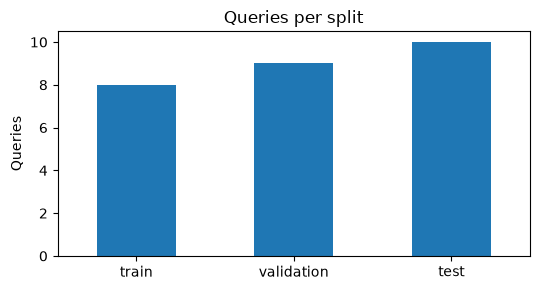

label,0,1
split,,
test,56,8
train,56,8
validation,56,8


In [6]:
from statistics import median
for name, rows in [("found", found), ("lost", lost)]:
    lengths = [len(row["description"]) for row in rows]
    print(name, "description length min/median/max:", min(lengths), median(lengths), max(lengths))
split_counts = pd.Series({s: sum(q["split"] == s for q in queries) for s in ["train","validation","test"]})
ax = split_counts.plot(kind="bar", figsize=(5.5,3), rot=0, title="Queries per split")
ax.set_ylabel("Queries")
plt.tight_layout()
plt.show()
display(pd.DataFrame(labels).groupby(["split","label"]).size().unstack(fill_value=0))

**What we learn:** descriptions are short, and each split contains far more incorrect pairs than correct pairs (56 versus 8). This matters because a classifier could favour the majority class. We use balanced class weights for Logistic Regression.

## 3. Modelling: Logistic Regression base model

### Why did we start with classification?
Our first approach asks whether a particular lost report and found report describe the same item. Logistic Regression is a **supervised** model, meaning it learns from pairs whose expected labels are already known.

A computer needs numbers rather than descriptions alone. **Feature engineering** means converting the reports into useful numerical signals:

- Description similarity: how many words the reports share (Jaccard similarity).
- Attribute agreement or disagreement: for example, whether categories, colours or brands match.
- Distinctive features, location similarity and the time difference between reports.

There are 14 features in total. Unknown attributes do not count as conflicts. The existing feature code uses a 48-hour default for missing timestamps.

### 3.1 Prepare the input to Logistic Regression
The next cell builds the training matrix (one row for each labelled pair and one column for each feature). It also defines the two simple comparison methods: keyword overlap and structured attribute matching.

In [7]:
from matching_system.logistic_regression_features import FEATURE_NAMES, pair_features
from matching_system.models import Report
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def tokens(value):
    from matching_system.nlp_retrieval import normalize_report_text
    return set(normalize_report_text(value).split())


def keyword(lost, found):
    left, right = tokens(lost["description"]), tokens(found["description"])
    return len(left & right) / len(left | right) if left and right else 0.0


def attributes(lost, found):
    score = 0.0
    for field, weight in (("category", 0.5), ("colour", 0.25), ("brand", 0.25)):
        a, b = lost.get(field, "").casefold(), found.get(field, "").casefold()
        if a and b:
            score += weight if a == b else -weight
    return max(0.0, score)


def as_report(row, kind):
    return Report(report_id=row[f"{kind}_id"], report_type=kind, description=row["description"],
                  category=row["category"], colour=row.get("colour", ""), brand=row.get("brand", ""),
                  location=row.get("last_seen_location" if kind == "lost" else "location", ""))

found = {row["found_id"]: row for row in found}
lost = {row["lost_id"]: row for row in lost}
pools = json.loads((DATA / "candidate_pools.json").read_text(encoding="utf-8"))
assert len(pools) == 1
found_ids = next(iter(pools.values()))
feature_cache = {}
for q in queries:
    for fid in found_ids:
        key = (q["lost_id"], fid)
        feature_cache[key] = pair_features(as_report(lost[key[0]], "lost"), as_report(found[fid], "found"))
training = [r for r in labels if r["split"] == "train" and r["label"] in {"0","1"}]
x_train = np.array([[feature_cache[(r["lost_id"], r["found_id"])][name] for name in FEATURE_NAMES] for r in training])
y_train = np.array([int(r["label"]) for r in training])
print("Training matrix:", x_train.shape, "| positive labels:", int(y_train.sum()))
display(pd.DataFrame(x_train[:3], columns=FEATURE_NAMES).T.rename(columns={0:"pair 1",1:"pair 2",2:"pair 3"}))

Training matrix: (64, 14) | positive labels: 8


,pair 1,pair 2,pair 3
description_similarity,0.272727,0.0,0.0
category_match,1.000000,0.0,0.0
category_conflict,0.000000,1.0,1.0
colour_match,1.000000,0.0,0.0
colour_conflict,0.000000,1.0,1.0
brand_match,0.000000,0.0,0.0
brand_conflict,0.000000,0.0,0.0
model_match,0.000000,0.0,0.0
model_conflict,0.000000,0.0,0.0
material_match,0.000000,0.0,0.0


### 3.2 Train the classifier
The training matrix has 64 rows and 14 columns, with 8 positive labels. The next cell fits Logistic Regression to these numbers.

The model learns a **weight** (coefficient) for each feature. Positive weights increase the score; negative weights decrease it. Balanced class weights help prevent the more numerous negative pairs from dominating training. Logistic Regression uses a sigmoid function to turn the weighted sum into a score between 0 and 1; here the score ranks candidates, rather than proving ownership.

In [8]:
classifier = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
classifier.fit(x_train, y_train)
all_keys = list(feature_cache)
x_all = np.array([[feature_cache[key][name] for name in FEATURE_NAMES] for key in all_keys])
classifier_scores = dict(zip(all_keys, classifier.predict_proba(x_all)[:,1]))
print("Model fitted. Feature count:", len(FEATURE_NAMES))
display(pd.DataFrame({"feature": FEATURE_NAMES, "coefficient": classifier.coef_[0]}).round(3))

Model fitted. Feature count: 14


,feature,coefficient
0,description_similarity,0.349
1,category_match,1.566
2,category_conflict,-1.566
3,colour_match,1.186
4,colour_conflict,-1.186
5,brand_match,0.315
6,brand_conflict,-0.380
7,model_match,0.000
8,model_conflict,0.000
9,material_match,0.000


**What the coefficients tell us:** category agreement and colour agreement have relatively large positive weights, while disagreements reduce the score. Some features have zero weights because the controlled dataset does not provide useful variation for them. These learned weights are specific to this benchmark. The original historical experiment remains in the separate baseline notebook.

## 4. Modelling: implement NLP with TF-IDF

### Why use natural language processing?
Students may describe the same item in different ways. NLP lets us compare the text itself, even when we do not have a large collection of labelled report pairs.

The final application uses a lightweight text-ranking method. It can build a vocabulary from the current inventory without retraining a supervised pair classifier. It is easy to run locally and to explain. These are practical reasons for using TF-IDF, not proof that it is the most accurate method.

### 4.1 From words to numbers

| Step | Simple explanation |
|---|---|
| Normalize text | Lowercase words, remove punctuation and tidy spaces; e.g. “BLACK HP Laptop-Charger!” → “black hp laptop charger”. |
| Tokenize | Break text into words. A unigram is one word; a bigram is a two-word phrase, such as “laptop charger”. |
| TF-IDF | Give higher weight to words or phrases that are important in one description but uncommon across the collection. |
| Cosine similarity | Compare two numerical text vectors. Higher scores mean more similar weighted words; zero means no shared weighted terms. |

TF-IDF stands for **term frequency–inverse document frequency**. Term frequency measures how often a term occurs; inverse document frequency reduces the influence of very common terms. Scikit-learn uses smoothed IDF: idf(t) = ln((1 + N)/(1 + df(t))) + 1, where N is the number of documents and df(t) counts documents containing the term. It then normalizes vector lengths. Cosine similarity divides the vectors' dot product by their lengths.

### 4.2 Fit the text model and calculate similarity
For the offline experiment, fit the vocabulary on training descriptions only. Scikit-learn lowercases, tokenizes, strips accents and uses unigrams and bigrams. Then transform all descriptions with that vocabulary and calculate a similarity score for every query and candidate.

The actual application additionally applies the explicit text normalization function to item names and descriptions and fits on current found inventory. We show that path in section 7.

In [9]:
from matching_system.nlp_retrieval import normalize_report_text
train_found = [r for r in found.values() if r["split"] == "train"]
train_lost = [r for r in lost.values() if r["split"] == "train"]
vectorizer = TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode")
vectorizer.fit([r["description"] for r in train_found + train_lost])
found_matrix = vectorizer.transform([found[fid]["description"] for fid in found_ids])
lost_matrix = vectorizer.transform([lost[q["lost_id"]]["description"] for q in queries])
cosine = cosine_similarity(lost_matrix, found_matrix)
print("Normalization:", normalize_report_text("BLACK HP Laptop-Charger!"))
print("Training documents:", len(train_found) + len(train_lost), "| vocabulary:", len(vectorizer.vocabulary_))
print("Found vector shape:", found_matrix.shape, "| similarity matrix:", cosine.shape)
display(pd.DataFrame(cosine[:3,:5], index=[q["lost_id"] for q in queries[:3]], columns=found_ids[:5]).round(3))

Normalization: black hp laptop charger
Training documents: 16 | vocabulary: 205
Found vector shape: (24, 205) | similarity matrix: (27, 24)


,f-g001,f-g002,f-g003,f-g004,f-g005
l-g001,0.107,0.0,0.00,0.0,0.0
l-g002,0.000,0.0,0.00,0.0,0.0
l-g003,0.000,0.0,0.06,0.0,0.0


**Reading the output:** the 16 training descriptions produce 205 vocabulary terms. Each found report is represented by a vector of 205 numbers. The similarity matrix contains 27 rows (lost queries) and 24 columns (found candidates). Each number is a text similarity score, not a probability of ownership.

## 5. Validation and model selection

### Which approach should we compare?
All five approaches rank the same candidate inventory so we can compare them fairly on the controlled queries.

| Method | How it produces a score |
|---|---|
| Keyword overlap | Shared words divided by the total unique words. |
| Structured attributes | Category (0.50), colour (0.25) and brand (0.25); disagreements subtract weight. |
| Logistic Regression | A score learned from labelled pairs and numerical features. |
| TF-IDF | Cosine similarity between description vectors. |
| Hybrid | A weighted combination of TF-IDF and structured scores. |

### How do we measure a ranking?
- **Top-1:** Did the correct item appear first?
- **Recall@5:** Did we find the correct item among the first five? Each matched query has one correct item in this dataset.
- **MRR (mean reciprocal rank):** How early does the correct item appear? Rank 1 contributes 1, rank 2 contributes 1/2, and rank 3 contributes 1/3.
- **False suggestions:** For a query with no matching item, did the top score exceed the experimental cutoff?

The next cell tries hybrid text weights of 0.25, 0.50 and 0.75 on the validation set. It chooses the highest Recall@5, then MRR, then the smaller text weight if tied. We do not use the test set to choose these settings.

In [10]:
def ranking_metrics(queries, scores, found_ids):
    matched, unmatched = [], []
    for query in queries:
        ranked = sorted(found_ids, key=lambda fid: (-scores[(query["lost_id"], fid)], fid))
        relevant = set(filter(None, query["relevant_found_ids"].split("|")))
        top = scores[(query["lost_id"], ranked[0])] if ranked else 0.0
        if relevant:
            positions = [i + 1 for i, fid in enumerate(ranked) if fid in relevant]
            matched.append({"query_id": query["query_id"], "first_rank": min(positions) if positions else None,
                            "recall_at_5": len([p for p in positions if p <= 5]) / len(relevant)})
        else:
            unmatched.append({"query_id": query["query_id"], "top_score": top})
    n = len(matched)
    return {"matched_queries": n, "no_match_queries": len(unmatched), "candidate_pool_size": len(found_ids),
            "top1_accuracy": sum(row["first_rank"] == 1 for row in matched) / n if n else None,
            "recall_at_5": sum(row["recall_at_5"] for row in matched) / n if n else None,
            "mrr": sum(1 / row["first_rank"] if row["first_rank"] else 0 for row in matched) / n if n else None,
            "matched_details": matched, "no_match_details": unmatched}

scores = {name: {} for name in ("keyword", "attributes", "logistic_regression", "tfidf", "hybrid")}
for qi, q in enumerate(queries):
    for fi, fid in enumerate(found_ids):
        key = (q["lost_id"], fid)
        scores["keyword"][key] = keyword(lost[key[0]], found[fid])
        scores["attributes"][key] = attributes(lost[key[0]], found[fid])
        scores["logistic_regression"][key] = float(classifier_scores[key])
        scores["tfidf"][key] = float(cosine[qi, fi])
validation = [q for q in queries if q["split"] == "validation"]
choices = []
for weight in (0.25, 0.5, 0.75):
    candidate = {key: weight * scores["tfidf"][key] + (1 - weight) * scores["attributes"][key] for key in all_keys}
    metric = ranking_metrics(validation, candidate, found_ids)
    choices.append((metric["recall_at_5"], metric["mrr"], weight, candidate))
_, _, weight, scores["hybrid"] = max(choices, key=lambda item: (item[0], item[1], -item[2]))
display(pd.DataFrame([{"TF-IDF weight": w, "Validation Recall@5": recall, "Validation MRR": mrr}
                       for recall, mrr, w, _ in choices]).round(3))
print("Selected hybrid TF-IDF weight:", weight)

,TF-IDF weight,Validation Recall@5,Validation MRR
0,0.25,1.0,1.000
1,0.50,1.0,1.000
2,0.75,1.0,0.906


Selected hybrid TF-IDF weight: 0.25


**Chosen validation setting:** the hybrid uses 25% TF-IDF and 75% structured attributes. The 0.25 and 0.50 options both scored 1.000 for validation Recall@5 and MRR; the stated tie-break rule selected 0.25. This selects an experimental hybrid setting, not the operational model. The application currently uses pure text ranking with separate knowledge checks.

## 6. Held-out testing and evaluation

### How well do the methods work on new queries?
After choosing the experimental settings, we evaluate on 10 test queries: eight with a known match and two with none.

For this offline experiment, rank all 24 candidates, including candidates with zero scores. We set each method's no-match cutoff just above the highest score of the single validation no-match query. A cutoff is a score boundary used to decide whether a suggestion is strong enough. This experimental cutoff is not used by the application.

The next cell calculates the test results and checks that the notebook's implementation agrees with the maintained evaluator. The chart then compares Top-1, Recall@5 and MRR across the methods.

In [11]:
output = {"provenance": "AI-authored controlled fiction; no real-campus accuracy claim",
          "dataset": validation_audit["counts"], "sklearn_version": sklearn.__version__,
          "tfidf": {"fit_split": "train", "ngram_range": [1, 2], "vocabulary_size": len(vectorizer.vocabulary_)},
          "logistic_regression": {"fit_split": "train", "pair_count": len(training), "features": list(FEATURE_NAMES)},
          "hybrid": {"tfidf_weight_selected_on_validation": weight}, "methods": {}}
for name, method_scores in scores.items():
    val = ranking_metrics(validation, method_scores, found_ids)
    no_match_top = [row["top_score"] for row in val["no_match_details"]]
    threshold = max(no_match_top, default=0.0) + 1e-9
    test = ranking_metrics([q for q in queries if q["split"] == "test"], method_scores, found_ids)
    false_suggestions = sum(row["top_score"] >= threshold for row in test["no_match_details"])
    output["methods"][name] = {"validation": val, "test": test,
                                "strong_match_threshold_from_validation": threshold,
                                "test_no_match_false_suggestions": false_suggestions,
                                "test_no_match_denominator": test["no_match_queries"]}
results = output
summary = pd.DataFrame([
    {"Method": name, "Top-1": info["test"]["top1_accuracy"],
     "Recall@5": info["test"]["recall_at_5"], "MRR": info["test"]["mrr"],
     "False suggestions": f"{info['test_no_match_false_suggestions']}/{info['test_no_match_denominator']}"}
    for name, info in results["methods"].items()
]).set_index("Method")
display(summary.round(3))
(RUN_DIR / "ranking_benchmark.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
# Check the visible notebook implementation against the maintained evaluator.
from scripts.evaluate_ranking_benchmark import main as maintained_evaluator
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    reference = maintained_evaluator(DATA, RUN_DIR / "reference_results.json")
for name in results["methods"]:
    for metric in ["top1_accuracy", "recall_at_5", "mrr"]:
        assert np.isclose(results["methods"][name]["test"][metric],
                          reference["methods"][name]["test"][metric]), (name, metric)
    assert results["methods"][name]["test_no_match_false_suggestions"] == reference["methods"][name]["test_no_match_false_suggestions"]
print("Visible notebook comparison agrees with the maintained evaluator.")

,Top-1,Recall@5,MRR,False suggestions
Method,,,,
keyword,0.25,0.875,0.541,1/2
attributes,1.00,1.000,1.000,1/2
logistic_regression,1.00,1.000,1.000,1/2
tfidf,0.25,0.500,0.391,2/2
hybrid,1.00,1.000,1.000,2/2


Visible notebook comparison agrees with the maintained evaluator.


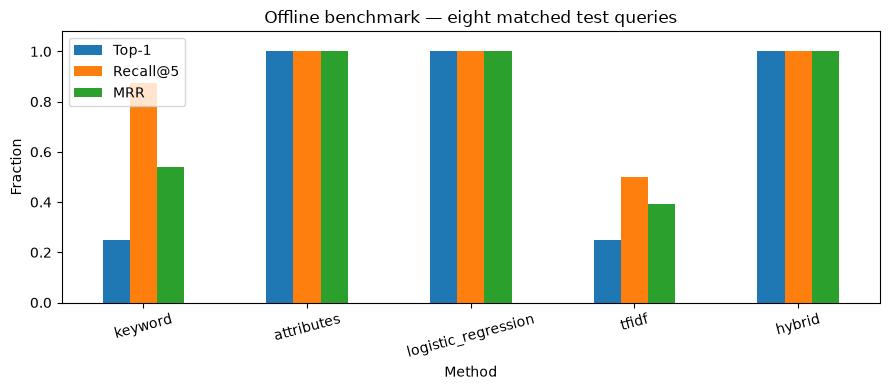

In [12]:
ax = summary[["Top-1","Recall@5","MRR"]].plot(kind="bar", figsize=(9,4), rot=15)
ax.set(title="Offline benchmark — eight matched test queries", ylabel="Fraction", ylim=(0,1.08))
plt.tight_layout()
plt.show()

### 6.1 What do these test results mean?
Structured attributes, Logistic Regression and hybrid ranked all eight known matches first. Offline TF-IDF ranked two first and retrieved four within the first five.

The perfect scores should not be read as 100% accuracy at Strathmore: the fictional examples reuse structured details, making some pairs easy to distinguish. All methods made false suggestions on at least one no-match query. The text-only approach is weaker on paraphrased descriptions.

The results show that structured information is useful. They do not show that TF-IDF is the best-performing method. We retain TF-IDF as the simple operational prototype because it can rank new free-text descriptions from an updated inventory with no supervised pair-model retraining. Further evidence is needed before choosing a stronger production method.

## 7. Implement the operational NLP ranker and explain its results

### What happens when a student reports a lost item?
1. Read the item name and description of every active found report.
2. Normalize the text and fit the TF-IDF vocabulary to this found inventory.
3. Convert the lost description into the same numerical representation.
4. Calculate cosine similarity and return up to five positive-scoring candidates, highest score first (ties are ordered by ID).
5. Check category, location and event date, then produce a plain-language explanation.

The last step is **explainable AI (XAI)**: it helps office staff understand which facts agree, conflict or are unknown. These knowledge rules do not change the ranking or authorize item release. No image model is used.

The following cell demonstrates the numerical steps using a test report. It also calls the actual TfidfMatcher used by the worker and checks that both implementations return candidates in the same order.

In [13]:
from matching_system.nlp_retrieval import TextReport
from matching_system.matching_agent import assess_candidate
from matching_system.staff_workflow_agent import recommend_staff_workflow
from matching_system.pipeline import explain_candidate
from service.inference import TfidfMatcher

def runtime_row(row, kind):
    return {"id": row[f"{kind}_id"], "report_type": kind,
            "description": row["description"], "item_name": row.get("item_name", ""),
            "category_id": row.get("category") or None,
            "location_id": row.get("last_seen_location" if kind == "lost" else "location") or None,
            "event_date": row.get("date_lost" if kind == "lost" else "event_date") or None}

def to_text_report(row):
    return TextReport(row["id"], row["report_type"], row["description"],
                      item_name=row.get("item_name", ""), category_id=row.get("category_id"),
                      location_id=row.get("location_id"), event_date=row.get("event_date"))

inventory_rows = [runtime_row(found[fid], "found") for fid in found_ids]
query_row = runtime_row(lost["l-g017"], "lost")
corpus = [normalize_report_text(f"{row['item_name']} {row['description']}") for row in inventory_rows]
query_text = normalize_report_text(f"{query_row['item_name']} {query_row['description']}")
live_vectorizer = TfidfVectorizer(ngram_range=(1,2), strip_accents="unicode")
inventory_matrix = live_vectorizer.fit_transform(corpus)
query_vector = live_vectorizer.transform([query_text])
similarities = cosine_similarity(query_vector, inventory_matrix)[0]
ordered = sorted([(row, float(score)) for row, score in zip(inventory_rows, similarities) if score > 0],
                 key=lambda pair: (-pair[1], pair[0]["id"]))[:5]
actual = TfidfMatcher().recommend(query_row, inventory_rows)
assert [row["id"] for row, _ in ordered] == [r["found_report_id"] for r in actual]
for row, score in ordered:
    assessment = assess_candidate(to_text_report(query_row), to_text_report(row), round(score, 6))
    workflow = recommend_staff_workflow(assessment)
    print(row["id"], "score:", round(score, 6), "|", explain_candidate(assessment, workflow))
if actual:
    display(pd.DataFrame(actual[0]["facts"]))
print("Operational candidate order verified against the deployed-code ranker (in process).")

f-g023 score: 0.219556 | Facts: category differs; location agrees; event date is missing or unknown. Staff should review the conflicting details. Text similarity is lexical evidence, not a probability. Ownership is unverified; release is not authorized.
f-g006 score: 0.196663 | Facts: category differs; location agrees; event date is missing or unknown. Staff should review the conflicting details. Text similarity is lexical evidence, not a probability. Ownership is unverified; release is not authorized.
f-g017 score: 0.192311 | Facts: category agrees; location agrees; event date is missing or unknown. Staff should request or verify additional details. Text similarity is lexical evidence, not a probability. Ownership is unverified; release is not authorized.
f-g004 score: 0.184759 | Facts: category differs; location differs; event date is missing or unknown. Staff should review the conflicting details. Text similarity is lexical evidence, not a probability. Ownership is unverified; relea

,fact_id,status,lost_value,found_value,reason_code
0,category_id,conflict,plastic_water_bottle,calculator,CATEGORY_CONFLICT
1,location_id,agreement,cafeteria,cafeteria,LOCATION_AGREEMENT
2,event_date,unknown,NaN,NaN,EVENT_DATE_UNKNOWN


Operational candidate order verified against the deployed-code ranker (in process).


**Example:** for the test query ending in g017, the correct found report is third, while the first two results share text but have conflicting categories. The explanation makes this visible: a similar description is not necessarily the same item. Staff should check the supporting facts rather than automatically accepting the first result.

### 7A. Test the NLP ranker used by the application

The actual service fits its vocabulary differently from the offline experiment, so we test it separately. The next cell calls TfidfMatcher on all ten test queries with the same 24-item inventory. Our controlled dataset has descriptions but no separate item-name field, so that field is left blank.

The operational ranker returns only positive-scoring candidates (up to five). MRR@5 is zero for an item missing from those five. For no-match queries, any returned candidate counts as a false suggestion because the operational service does not apply the offline cutoff.

In [14]:
pool = pools
matcher = TfidfMatcher()
details = []
for q in queries:
    if q['split'] != 'test':
        continue
    inventory_rows = [runtime_row(found[fid], 'found') for fid in pool[q['candidate_pool_id']]]
    ranked = matcher.recommend(runtime_row(lost[q['lost_id']], 'lost'), inventory_rows)
    ids = [m['found_report_id'] for m in ranked]
    relevant = set(filter(None, q['relevant_found_ids'].split('|')))
    positions = [i + 1 for i, fid in enumerate(ids) if fid in relevant]
    details.append({'query': q['query_id'], 'has_match': bool(relevant),
                    'first_rank': min(positions) if positions else None,
                    'recall5': len(positions)/len(relevant) if relevant else None,
                    'candidate_count': len(ids),
                    'top_score': ranked[0]['text_similarity'] if ranked else None,
                    'top_candidate': ids[0] if ids else None,
                    'explanation': ranked[0]['explanation'] if ranked else 'No lexical candidates'})
matched = [d for d in details if d['has_match']]
unmatched = [d for d in details if not d['has_match']]
assert len(matched) == 8 and len(unmatched) == 2
print('Operational model:', matcher.version)
print('Top-1:', sum(d['first_rank'] == 1 for d in matched)/len(matched))
print('Recall@5:', sum(d['recall5'] for d in matched)/len(matched))
print('MRR@5:', sum(1/d['first_rank'] if d['first_rank'] else 0 for d in matched)/len(matched))
print('No-match queries with suggestions:', sum(d['candidate_count'] > 0 for d in unmatched), '/', len(unmatched))
display(pd.DataFrame(details).drop(columns='explanation'))
print('Example explanation:', details[0]['explanation'])

Operational model: tfidf-knowledge-agents-v1
Top-1: 0.5
Recall@5: 0.875
MRR@5: 0.6291666666666667
No-match queries with suggestions: 2 / 2


,query,has_match,first_rank,recall5,candidate_count,top_score,top_candidate
0,q-g017,True,3.0,1.0,5,0.219556,f-g023
1,q-g018,True,NaN,0.0,5,0.221528,f-g002
2,q-g019,True,2.0,1.0,5,0.356514,f-g011
3,q-g020,True,5.0,1.0,5,0.364054,f-g013
4,q-g021,True,1.0,1.0,3,0.178991,f-g021
5,q-g022,True,1.0,1.0,4,0.339898,f-g022
6,q-g023,True,1.0,1.0,5,0.350145,f-g023
7,q-g024,True,1.0,1.0,3,0.221702,f-g024
8,q-nm002,False,NaN,NaN,5,0.439738,f-g008
9,q-nm003,False,NaN,NaN,5,0.509562,f-g015


Example explanation: Facts: category differs; location agrees; event date is missing or unknown. Staff should review the conflicting details. Text similarity is lexical evidence, not a probability. Ownership is unverified; release is not authorized.


**What the application ranker achieved:**

| Metric | Result | Meaning |
|---|---:|---|
| Top-1 | 4/8 (50%) | The correct item appeared first for four matched queries. |
| Recall@5 | 7/8 (87.5%) | The correct item appeared somewhere in the first five for seven queries. |
| MRR@5 | 0.629 | Rewards correct items that appear nearer the top. |
| False suggestions | 2/2 | Both queries without a match still received candidates. |

This is stronger retrieval than the offline TF-IDF experiment on these examples, but not a guarantee of reliable matching in the university. We need a better way to recognize when there is no suitable match. These tests measure the ranker, not the Android device or Firestore connection.

## 8. Integration and input validation

### Can the system handle valid and invalid reports?
An application must reject incomplete or impossible input instead of passing it to the model. The next cell tests a valid water-bottle report, a blank description and an impossible calendar date using the local preview functions.

The preview runs the matching logic without signing in users or saving their reports. It is a useful input check, but it is not the complete Android workflow.

In [15]:
from pydantic import ValidationError
from matching_system.api import PreviewRequest, preview_matches
request = PreviewRequest(item_name='Metal water bottle',description='Blue bottle with a scratched lid',category_id='metal_water_bottle',location_id='msb',event_date='2026-11-10',limit=3)
body = preview_matches(request)
print('status:', body['status'], 'first ID:', body['matches'][0]['found_report_id'])
print('explanation:', body['matches'][0]['explanation'])
for label, values in [('blank description', {'item_name':'Water bottle','description':''}), ('invalid calendar date', {'item_name':'Water bottle','description':'Blue bottle','event_date':'2026-02-30'})]:
    try:
        PreviewRequest(**values)
    except ValidationError:
        print(label + ': rejected')

status: possible_matches first ID: demo-found-metal
explanation: Facts: category agrees; location differs; event date agrees. Staff should review the conflicting details. Text similarity is lexical evidence, not a probability. Ownership is unverified; release is not authorized.
blank description: rejected
invalid calendar date: rejected


**Result:** the valid report produced a possible match with an explanation; both invalid inputs were rejected. This confirms the preview validation worked for these examples.

### 8A. Connect the model to the application

The actual local demonstration connects the Android app to the authenticated FastAPI service on port 8000, Firebase emulators and the separate NLP worker. FastAPI receives and validates reports; Firestore stores them; the worker runs the ranker and saves suggestions.

See [local presentation instructions](../docs/LOCAL_PRESENTATION.md). The backend integration test passed: two exact-description charger reports returned the intended top results, and a blank description returned HTTP 422 (invalid input). [Test evidence](https://github.com/nimrod-kobia/SemProject_MLEngine/actions/runs/45504542376). The Android device demonstration still needs to be rehearsed.

**Optional preview:** the next cell can also check the preview HTTP endpoint. Start `python -m uvicorn matching_system.api:app --host 127.0.0.1 --port 8001` and set NLP_LIVE_HTTP_DEMO=1 before launching the kernel. This optional check was skipped in the saved run. It is not the authenticated mobile API.

For the assessment, demonstrate the actual app with two different valid descriptions, invalid input and the explanations shown to users. All three presenters should participate.

In [16]:
import os
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def post_preview(payload):
    req = Request('http://127.0.0.1:8001/preview/matches', data=json.dumps(payload).encode('utf-8'), headers={'Content-Type':'application/json'}, method='POST')
    try:
        with urlopen(req, timeout=5) as response:
            return response.status, json.loads(response.read().decode('utf-8'))
    except HTTPError as error:
        return error.code, json.loads(error.read().decode('utf-8'))

if os.environ.get('NLP_LIVE_HTTP_DEMO') == '1':
    valid = {'item_name':'Metal water bottle','description':'Blue bottle with a scratched lid','category_id':'metal_water_bottle','location_id':'msb','event_date':'2026-11-10','limit':3}
    status, result = post_preview(valid)
    print('valid request:', status, result['status'], 'candidate count:', len(result['matches']))
    print('first explanation:', result['matches'][0]['explanation'] if result['matches'] else 'No candidate in the demo inventory')
    print('blank description:', post_preview({**valid, 'description':''})[0])
    print('invalid date:', post_preview({**valid, 'event_date':'2026-02-30'})[0])
else:
    print('Live HTTP check skipped. Start the local API and set NLP_LIVE_HTTP_DEMO=1 to run it.')

Live HTTP check skipped. Start the local API and set NLP_LIVE_HTTP_DEMO=1 to run it.


## 9. Interpretation and next steps

### What have we achieved?
We developed a working text-ranking prototype, tested it against simpler and supervised methods, and checked that its implementation produces explanations to support office staff. The operational ranker retrieved seven of eight known matches within five suggestions on the controlled test set.

### What still needs improvement?
- **Dataset:** independently review the constructed labels and collect permitted genuine matched reports for a larger independent test.
- **Language:** account for synonyms and paraphrases that share few words.
- **No-match handling:** improve rejection of unrelated suggestions using separately validated settings.
- **Application:** rehearse the complete device-to-worker workflow before the presentation.

The model helps staff find possible matches. It does not verify ownership, guarantee a match, or replace human review.

**Submission checklist:** historical base notebook retained; all data mining stages and actual model logic shown in this notebook; all 16 code cells executed successfully with saved outputs; optional preview HTTP check skipped by design; application rehearsal remains separate. Review the results and follow the instructor's AI-use requirements.